# 08 — Figuras e tabelas do artigo (IEEE/IFIP NOMS)

Gera apenas as saídas do artigo: `fig1_concentration`, `fig2_dependency`, `fig3_redundancy`,
`tab1_concentration.tex` e `tab2_dependency.tex`. Escopo: IPv4; peso fracionado; blocos US, EU, BRICS, Others.

## Seção 0: configuração

In [15]:
# =============================================================================
# SEÇÃO 0: CONFIGURAÇÃO
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# pastas de saída
PASTA_FIG = Path("../outputs/figures")
PASTA_TAB = Path("../outputs/tables")
PASTA_FIG.mkdir(parents=True, exist_ok=True)
PASTA_TAB.mkdir(parents=True, exist_ok=True)

# --- países e blocos ---------------------------------------------------------
# país da empresa vem por extenso; país do provedor vem em ISO2
PAIS_ISO2 = {
    "Argentina": "AR", "Australia": "AU", "Austria": "AT", "Bahamas": "BS", "Bahrain": "BH",
    "Belgium": "BE", "Bermuda": "BM", "Brazil": "BR", "British Virgin Islands": "VG",
    "Bulgaria": "BG", "Canada": "CA", "Cayman Islands": "KY", "Chile": "CL", "China": "CN",
    "Colombia": "CO", "Costa Rica": "CR", "Cyprus": "CY", "Czech Republic": "CZ",
    "Denmark": "DK", "Egypt": "EG", "Estonia": "EE", "Finland": "FI", "France": "FR",
    "Germany": "DE", "Gibraltar": "GI", "Greece": "GR", "Guernsey": "GG", "Hong Kong": "HK",
    "Hungary": "HU", "Iceland": "IS", "India": "IN", "Indonesia": "ID", "Ireland": "IE",
    "Isle of Man": "IM", "Israel": "IL", "Italy": "IT", "Japan": "JP", "Jersey": "JE",
    "Jordan": "JO", "Kazakhstan": "KZ", "Kuwait": "KW", "Latvia": "LV",
    "Liechtenstein": "LI", "Lithuania": "LT", "Luxembourg": "LU", "Macau": "MO",
    "Malaysia": "MY", "Malta": "MT", "Mexico": "MX", "Monaco": "MC", "Netherlands": "NL",
    "New Zealand": "NZ", "Norway": "NO", "Panama": "PA", "Peru": "PE", "Philippines": "PH",
    "Poland": "PL", "Portugal": "PT", "Qatar": "QA", "Romania": "RO", "Saudi Arabia": "SA",
    "Singapore": "SG", "South Africa": "ZA", "South Korea": "KR", "Spain": "ES",
    "Sweden": "SE", "Switzerland": "CH", "Taiwan": "TW", "Thailand": "TH", "Turkey": "TR",
    "United Arab Emirates": "AE", "United Kingdom": "GB", "United States": "US",
    "Uruguay": "UY", "Vietnam": "VN", "Russia": "RU", "Ethiopia": "ET", "Iran": "IR",
}

UE27 = {"AT", "BE", "BG", "HR", "CY", "CZ", "DK", "EE", "FI", "FR", "DE", "GR", "HU", "IE",
        "IT", "LV", "LT", "LU", "MT", "NL", "PL", "PT", "RO", "SK", "SI", "ES", "SE"}

# BRICS: 5 membros originais + membros plenos de 2024/2025 (sem a Arábia Saudita; parceiros não entram)
BRICS = {"BR", "RU", "IN", "CN", "ZA", "EG", "ET", "IR", "AE", "ID"}


def bloco_de(pais):
    """Código ISO2 -> bloco: US, EU, BRICS ou Others."""
    if pais == "US":
        return "US"
    if pais in UE27 or pais == "EU":   # "EU" = registro regional europeu no WHOIS
        return "EU"
    if pais in BRICS:
        return "BRICS"
    return "Others"


BLOCOS = ["US", "EU", "BRICS", "Others"]
ORDEM_BLOCOS = BLOCOS + ["Total"]

# nomes curtos dos provedores nas figuras (quem não está aqui aparece com o nome original)
NOME_CURTO = {
    "Amazon.com, Inc.": "AWS",
    "Cloudflare, Inc.": "Cloudflare",
    "Microsoft Corporation": "Microsoft",
    "DigiCert": "DigiCert",
    "Akamai": "Akamai",
    "Alibaba": "Alibaba",
    "Tencent": "Tencent",
    "China Telecom": "China Telecom",
    "China Unicom": "China Unicom",
    "China Mobile": "China Mobile",
    "China Networks Inter-Exchange": "CNIX",
    "GoDaddy": "GoDaddy",
    "NSONE Inc": "NS1",
    "Internet Initiative Japan Inc.": "IIJ",
    "Host Europe GmbH": "Host Europe",
    "ipcom GmbH": "ipcom",
    "IONOS / United Internet": "IONOS",
}

# --- padrão visual NOMS -------------------------------------------------------
W1, W2 = 3.5, 7.16   # largura de uma coluna / figure* (in)

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "lines.linewidth": 0.6,
    "patch.linewidth": 0.6,
    "hatch.linewidth": 0.6,
    "axes.grid": False,          # a grade é ligada em cada gráfico, só no eixo de valores
    "grid.linewidth": 0.4,
    "grid.color": "#dddddd",
    "axes.axisbelow": True,
    "pdf.fonttype": 42,          # TrueType no PDF (sem Type 3)
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})
TAM_ROTULO = 7   # pt dos rótulos de valor

# paleta Okabe-Ito, sempre com o mesmo significado
COR_BLOCO = {"US": "#0072B2", "EU": "#E69F00", "BRICS": "#009E73", "Others": "#999999"}

SITUACOES = ["Domestic only", "Foreign + domestic alternative",
             "Foreign only (2+ providers)", "Foreign only (single provider)"]
COR_SITUACAO = dict(zip(SITUACOES, ["#0072B2", "#56B4E9", "#E69F00", "#D55E00"]))
HATCH_SITUACAO = dict(zip(SITUACOES, ["", "///", "...", "xxx"]))   # leitura em cinza

CMAP_HEATMAP = "Blues"
PONDERACOES = {"valor_empresas": "By companies", "valor_receita": "By revenue"}


def cor_texto(cor_fundo):
    """Preto ou branco, o que der mais contraste com o fundo (luminância relativa, WCAG)."""
    rgb = np.array(mpl.colors.to_rgb(cor_fundo))
    lin = np.where(rgb <= 0.03928, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    lum = lin @ [0.2126, 0.7152, 0.0722]
    return "white" if lum < 0.179 else "black"


def rotulo_bloco(bloco, n):
    """'US (n=3,257)'."""
    return f"{bloco} (n={n:,})"


def salvar_figura(fig, nome):
    """Salva PDF vetorial (artigo) e PNG 300 dpi (conferência)."""
    fig.savefig(PASTA_FIG / f"{nome}.pdf")
    fig.savefig(PASTA_FIG / f"{nome}.png", dpi=300)


def salvar_tabela_latex(tabular, nome, label, larga=False, fonte=r"\footnotesize"):
    """Envolve o tabular em table/table* com caption e label placeholders e salva .tex."""
    amb = "table*" if larga else "table"
    tex = "\n".join([
        rf"\begin{{{amb}}}[t]",
        r"\centering",
        fonte,
        r"\caption{TODO}",
        rf"\label{{tab:{label}}}",
        tabular.strip(),
        rf"\end{{{amb}}}",
        "",
    ])
    (PASTA_TAB / f"{nome}.tex").write_text(tex, encoding="utf-8")
    print(tex)

## Seção 1: carga e tabela base

In [16]:
# =============================================================================
# SEÇÃO 1: CARGA E TABELA BASE
# =============================================================================
# dataset final: uma linha por empresa x NS x IP; fico só com IPv4
colunas = ["rank", "company_name", "company_country", "revenue_ttm", "ns", "ip_type",
           "asn", "dp_as_org", "dp_as_country_code"]
df = pd.read_parquet("../data/final/final_data.parquet", columns=colunas)
df = df[df["ip_type"] == "A"].copy()

# país e bloco da empresa (sede) e do provedor (grupo controlador do ASN)
df["pais_empresa"] = df["company_country"].map(PAIS_ISO2)
df["bloco_empresa"] = df["pais_empresa"].map(bloco_de)
df["provedor"] = df["dp_as_org"]
df["pais_provedor"] = df["dp_as_country_code"]
df["bloco_provedor"] = df["pais_provedor"].map(bloco_de)

print(f"{len(df):,} rows | {df['rank'].nunique():,} companies | {df['provedor'].nunique():,} providers")

# tabela empresa x provedor: nº de NS distintos da empresa em cada provedor
ep = (df.groupby(["rank", "provedor"], as_index=False)
        .agg(revenue_ttm=("revenue_ttm", "first"),
             pais_empresa=("pais_empresa", "first"),
             bloco_empresa=("bloco_empresa", "first"),
             pais_provedor=("pais_provedor", "first"),
             bloco_provedor=("bloco_provedor", "first"),
             n_ns=("ns", "nunique")))

# peso fracionado: n_ns / total de NS da empresa (soma 1 por empresa)
ep["peso"] = ep["n_ns"] / ep.groupby("rank")["n_ns"].transform("sum")

# as duas ponderações usadas em todas as métricas
ep["valor_empresas"] = ep["peso"]
ep["valor_receita"] = ep["peso"] * ep["revenue_ttm"]

# linhas duplicadas com bloco "Total": todo groupby por bloco já traz o total
base = pd.concat([ep, ep.assign(bloco_empresa="Total")], ignore_index=True)

# nº de empresas por bloco (rótulos "US (n=3,257)")
n_empresas = base.groupby("bloco_empresa")["rank"].nunique().reindex(ORDEM_BLOCOS)
display(n_empresas.to_frame("n_companies"))

44,069 rows | 10,283 companies | 1,112 providers


,n_companies
bloco_empresa,
US,3257
EU,1782
BRICS,1281
Others,3963
Total,10283


## Seção 2: concentração (subseção A)

In [17]:
# =============================================================================
# SEÇÃO 2A: TABELA I (CONCENTRAÇÃO), UMA COLUNA
# =============================================================================
# participação (%) de cada provedor dentro do bloco, nas duas ponderações
part = base.groupby(["bloco_empresa", "provedor"], as_index=False)[list(PONDERACOES)].sum()
for col in PONDERACOES:
    part[col] = 100 * part[col] / part.groupby("bloco_empresa")[col].transform("sum")


def metricas(shares):
    """HHI (0-10.000), N_eff e CRk a partir das participações (%) de um bloco."""
    s = shares.sort_values(ascending=False)
    hhi = (s ** 2).sum()
    return pd.Series({"HHI": hhi, "N_eff": 10_000 / hhi,
                      "CR1": s.iloc[:1].sum(), "CR5": s.iloc[:5].sum(), "CR10": s.iloc[:10].sum()})


n_provedores = part.groupby("bloco_empresa")["provedor"].nunique()

# uma tabela por ponderação (linhas = blocos)
tab1 = {nome_pond: part.groupby("bloco_empresa")[col].apply(metricas).unstack().reindex(ORDEM_BLOCOS)
        for col, nome_pond in PONDERACOES.items()}
display(pd.concat(tab1, axis=1).round(1))

# --- LaTeX: dois grupos de linhas (By companies / By revenue), 7 colunas ---
linhas = []
for g, (nome_pond, tab) in enumerate(tab1.items()):
    if g > 0:
        linhas.append(r"\midrule")
    linhas.append(rf"\multicolumn{{7}}{{l}}{{\textit{{{nome_pond}}}}} \\")
    for bloco, r in tab.iterrows():
        if bloco == "Total":
            linhas.append(r"\midrule")
        nome = rf"{bloco} ($n$={n_empresas[bloco]:,})" if g == 0 else bloco   # n só no 1º grupo
        vals = [f"{n_provedores[bloco]:,}", f"{r['HHI']:,.0f}", f"{r['N_eff']:.1f}",
                f"{r['CR1']:.1f}", f"{r['CR5']:.1f}", f"{r['CR10']:.1f}"]
        linhas.append(" & ".join([r"\quad " + nome] + vals) + r" \\")

tabular = "\n".join([
    r"\setlength{\tabcolsep}{4pt}",
    r"\begin{tabular}{lrrrrrr}",
    r"\toprule",
    r"Bloc & Providers & HHI & $N_{\mathrm{eff}}$ & CR1 & CR5 & CR10 \\",
    r"\midrule",
    *linhas,
    r"\bottomrule",
    r"\end{tabular}",
])
salvar_tabela_latex(tabular, "tab1_concentration", "concentration")

By companies                         By revenue              \
                       HHI N_eff   CR1   CR5  CR10        HHI N_eff   CR1   
bloco_empresa                                                               
US                  1552.2   6.4  29.2  78.0  88.6      951.0  10.5  19.4   
EU                   491.5  20.3  15.4  41.0  58.7      579.9  17.2  14.2   
BRICS                903.5  11.1  18.7  59.8  75.9     1032.0   9.7  23.5   
Others               865.3  11.6  21.1  54.7  68.7      731.4  13.7  16.0   
Total                878.6  11.4  22.1  57.3  69.1      626.1  16.0  15.0   

                           
                CR5  CR10  
bloco_empresa              
US             62.6  77.0  
EU             47.6  62.2  
BRICS          61.1  80.3  
Others         55.7  67.0  
Total          51.1  64.6

\begin{table}[t]
\centering
\footnotesize
\caption{TODO}
\label{tab:concentration}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{lrrrrrr}
\toprule
Bloc & Providers & HHI & $N_{\mathrm{eff}}$ & CR1 & CR5 & CR10 \\
\midrule
\multicolumn{7}{l}{\textit{By companies}} \\
\quad US ($n$=3,257) & 264 & 1,552 & 6.4 & 29.2 & 78.0 & 88.6 \\
\quad EU ($n$=1,782) & 400 & 491 & 20.3 & 15.4 & 41.0 & 58.7 \\
\quad BRICS ($n$=1,281) & 181 & 903 & 11.1 & 18.7 & 59.8 & 75.9 \\
\quad Others ($n$=3,963) & 472 & 865 & 11.6 & 21.1 & 54.7 & 68.7 \\
\midrule
\quad Total ($n$=10,283) & 1,112 & 879 & 11.4 & 22.1 & 57.3 & 69.1 \\
\midrule
\multicolumn{7}{l}{\textit{By revenue}} \\
\quad US & 264 & 951 & 10.5 & 19.4 & 62.6 & 77.0 \\
\quad EU & 400 & 580 & 17.2 & 14.2 & 47.6 & 62.2 \\
\quad BRICS & 181 & 1,032 & 9.7 & 23.5 & 61.1 & 80.3 \\
\quad Others & 472 & 731 & 13.7 & 16.0 & 55.7 & 67.0 \\
\midrule
\quad Total & 1,112 & 626 & 16.0 & 15.0 & 51.1 & 64.6 \\
\bottomrule
\end{tabular}
\end{table}



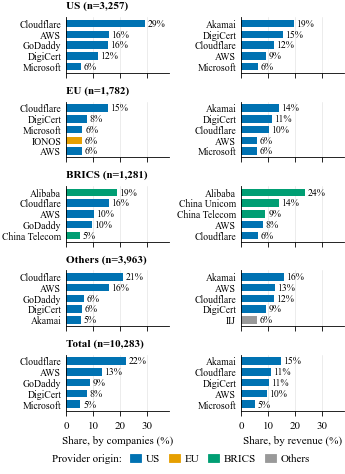

In [18]:
# =============================================================================
# SEÇÃO 2B: FIG. 1 (TOP 5 PROVEDORES POR BLOCO)
# =============================================================================
# uma coluna do artigo: cada linha é um bloco, e as duas colunas são as ponderações
TOP_N = 5
origem = ep.drop_duplicates("provedor").set_index("provedor")["bloco_provedor"]

fig, axes = plt.subplots(len(ORDEM_BLOCOS), 2, figsize=(W1, 4.8), sharex=True,
                         layout="constrained")

for i, bloco in enumerate(ORDEM_BLOCOS):
    for j, (col, nome_pond) in enumerate(PONDERACOES.items()):
        ax = axes[i, j]
        top = part[part["bloco_empresa"] == bloco].nlargest(TOP_N, col)
        nomes = top["provedor"].map(lambda p: NOME_CURTO.get(p, p))

        barras = ax.barh(nomes, top[col], color=top["provedor"].map(origem).map(COR_BLOCO),
                         height=0.7)
        ax.bar_label(barras, labels=[f"{v:.0f}%" for v in top[col]], padding=2,
                     fontsize=TAM_ROTULO)
        ax.invert_yaxis()                      # maior provedor em cima
        ax.grid(axis="x")
        ax.tick_params(axis="y", length=0, labelsize=TAM_ROTULO)

        if j == 0:                             # bloco no título do painel da esquerda
            ax.set_title(rotulo_bloco(bloco, n_empresas[bloco]), loc="left",
                         fontsize=8, fontweight="bold")
        if i == len(ORDEM_BLOCOS) - 1:         # ponderação no eixo x da última linha
            ax.set_xlabel(f"Share, {nome_pond.lower()} (%)")

# espaço à direita para os rótulos de valor
axes[0, 0].set_xlim(0, part[list(PONDERACOES)].max().max() * 1.3)
axes[0, 0].set_xticks([0, 10, 20, 30])

# legenda em uma linha só, com o título como primeiro item (economiza altura)
titulo = Patch(visible=False, label="Provider origin:")
fig.legend(handles=[titulo] + [Patch(color=COR_BLOCO[b], label=b) for b in BLOCOS],
           loc="outside lower center", ncol=len(BLOCOS) + 1, handlelength=1.0,
           columnspacing=0.8, handletextpad=0.4)

salvar_figura(fig, "fig1_concentration")
plt.show()

## Seção 3: dependência doméstica e estrangeira (subseção B)

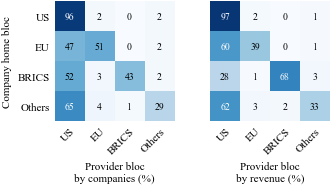

In [19]:
# =============================================================================
# SEÇÃO 3A: FIG. 2 (HEATMAP BLOCO DA EMPRESA x BLOCO DO PROVEDOR)
# =============================================================================
# % por linha: quanto do peso das empresas de cada bloco cai em provedores de cada bloco
fig, axes = plt.subplots(1, 2, figsize=(W1, 1.9), sharey=True, constrained_layout=True)

for ax, (col, nome_pond) in zip(axes, PONDERACOES.items()):
    matriz = (ep.pivot_table(index="bloco_empresa", columns="bloco_provedor", values=col,
                             aggfunc="sum", fill_value=0)
                .reindex(index=BLOCOS, columns=BLOCOS, fill_value=0))
    matriz = 100 * matriz.div(matriz.sum(axis=1), axis=0)     # cada linha soma 100%

    ax.imshow(matriz, cmap=CMAP_HEATMAP, vmin=0, vmax=100)
    for (i, j), v in np.ndenumerate(matriz.to_numpy()):       # % anotado em cada célula
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=TAM_ROTULO,
                color="white" if v > 55 else "black")

    ax.set_xticks(range(len(BLOCOS)), BLOCOS, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(len(BLOCOS)), BLOCOS)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_xlabel(f"Provider bloc\n{nome_pond.lower()} (%)")

axes[0].set_ylabel("Company home bloc")

salvar_figura(fig, "fig2_dependency")
plt.show()

In [20]:
# =============================================================================
# SEÇÃO 3B: TABELA II (DOMÉSTICO x ESTRANGEIRO POR EMPRESA)
# =============================================================================
# doméstico = provedor no mesmo país da sede da empresa
ep["domestico"] = ep["pais_provedor"] == ep["pais_empresa"]

# uma linha por empresa (usada também na Seção 4)
empresas = (ep.groupby("rank")
              .agg(bloco_empresa=("bloco_empresa", "first"),
                   revenue_ttm=("revenue_ttm", "first"),
                   todos_dom=("domestico", "all"),
                   algum_dom=("domestico", "any"),
                   algum_us=("pais_provedor", lambda p: (p == "US").any()),
                   n_provedores=("provedor", "nunique"))
              .reset_index())
empresas["dependencia"] = np.select([empresas["todos_dom"], empresas["algum_dom"]],
                                    ["Domestic only", "Mixed"], "Foreign only")
empresas_total = pd.concat([empresas, empresas.assign(bloco_empresa="Total")], ignore_index=True)

CATEG_DEP = ["Domestic only", "Mixed", "Foreign only"]


def pct_por_bloco(marcador, por_receita):
    """% (de empresas ou de receita) de cada bloco em que o marcador é verdadeiro."""
    peso = empresas_total["revenue_ttm"] if por_receita else 1
    num = (marcador * peso).groupby(empresas_total["bloco_empresa"]).sum()
    den = (pd.Series(1, index=empresas_total.index) * peso).groupby(empresas_total["bloco_empresa"]).sum()
    return 100 * num / den


tab2 = pd.concat({
    nome_pond: pd.DataFrame({**{c: pct_por_bloco(empresas_total["dependencia"] == c, por_receita)
                                for c in CATEG_DEP},
                             "Any US": pct_por_bloco(empresas_total["algum_us"], por_receita)})
    for nome_pond, por_receita in [("By companies", False), ("By revenue", True)]
}, axis=1).reindex(ORDEM_BLOCOS)
display(tab2.round(1))

# --- LaTeX: cabe em uma coluna com \scriptsize e \tabcolsep reduzido ---
linhas = []
for bloco, r in tab2.iterrows():
    if bloco == "Total":
        linhas.append(r"\midrule")
    vals = [f"{n_empresas[bloco]:,}"] + [f"{v:.1f}" for v in r]
    linhas.append(" & ".join([bloco] + vals) + r" \\")

cab = r"Dom. & Mixed & For. & Any US"
tabular = "\n".join([
    r"\setlength{\tabcolsep}{3pt}",
    r"\begin{tabular}{lrrrrrrrrr}",
    r"\toprule",
    r" & & \multicolumn{4}{c}{By companies (\%)} & \multicolumn{4}{c}{By revenue (\%)} \\",
    r"\cmidrule(lr){3-6} \cmidrule(lr){7-10}",
    rf"Bloc & $n$ & {cab} & {cab} \\",
    r"\midrule",
    *linhas,
    r"\bottomrule",
    r"\end{tabular}",
])
salvar_tabela_latex(tabular, "tab2_dependency", "dependency", fonte=r"\scriptsize")

By companies                              By revenue        \
              Domestic only Mixed Foreign only Any US Domestic only Mixed   
bloco_empresa                                                               
US                     95.7   0.5          3.7   96.3          96.5   1.2   
EU                     29.8  10.6         59.6   53.4          20.6  16.6   
BRICS                  41.1   3.8         55.1   54.3          62.6   8.6   
Others                 24.3   6.3         69.4   68.5          24.4  11.9   
Total                  50.0   4.9         45.1   72.9          56.7   8.2   

                                   
              Foreign only Any US  
bloco_empresa                      
US                     2.3   97.7  
EU                    62.7   71.0  
BRICS                 28.8   33.7  
Others                63.7   69.3  
Total                 35.2   74.5

\begin{table}[t]
\centering
\scriptsize
\caption{TODO}
\label{tab:dependency}
\setlength{\tabcolsep}{3pt}
\begin{tabular}{lrrrrrrrrr}
\toprule
 & & \multicolumn{4}{c}{By companies (\%)} & \multicolumn{4}{c}{By revenue (\%)} \\
\cmidrule(lr){3-6} \cmidrule(lr){7-10}
Bloc & $n$ & Dom. & Mixed & For. & Any US & Dom. & Mixed & For. & Any US \\
\midrule
US & 3,257 & 95.7 & 0.5 & 3.7 & 96.3 & 96.5 & 1.2 & 2.3 & 97.7 \\
EU & 1,782 & 29.8 & 10.6 & 59.6 & 53.4 & 20.6 & 16.6 & 62.7 & 71.0 \\
BRICS & 1,281 & 41.1 & 3.8 & 55.1 & 54.3 & 62.6 & 8.6 & 28.8 & 33.7 \\
Others & 3,963 & 24.3 & 6.3 & 69.4 & 68.5 & 24.4 & 11.9 & 63.7 & 69.3 \\
\midrule
Total & 10,283 & 50.0 & 4.9 & 45.1 & 72.9 & 56.7 & 8.2 & 35.2 & 74.5 \\
\bottomrule
\end{tabular}
\end{table}



## Seção 4: redundância (subseção C)

By companies                                         \
              Single provider              2+ providers                
                        Local Foreign only        Local Foreign only   
bloco_empresa                                                          
US                       91.2          2.4          5.1          1.4   
EU                       33.3         42.4         23.1          1.2   
BRICS                    27.5         52.4         17.6          2.6   
Others                   20.6         66.1         10.0          3.4   
Total                    46.0         40.1         11.7          2.2   

                   By revenue                                         
              Single provider              2+ providers               
                        Local Foreign only        Local Foreign only  
bloco_empresa                                                         
US                       75.2          0.9         22.4          1.4  
EU                       21.2         51.2         25.3          2.4  
BRICS                    32.3         26.3         38.9          2.5  
Others                   20.4         56.2         16.0          7.4  
Total                    42.8         30.1         23.5          3.6

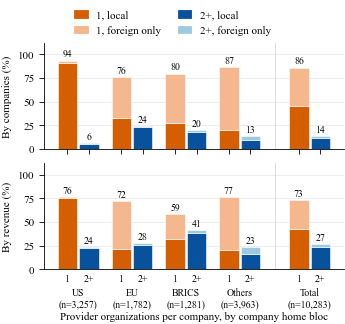

               % companies with 2+ NS  mean providers per company
bloco_empresa                                                    
US                              99.75                        1.07
EU                              99.83                        1.34
BRICS                           99.61                        1.43
Others                          99.24                        1.17
Total                           99.55                        1.20


In [21]:
# =============================================================================
# SEÇÃO 4: REDUNDÂNCIA (FIG. 3)
# =============================================================================
# redundância organizacional: todos os NS em uma única organização ou distribuídos em 2+
REDUNDANCIA = {"Single provider": "1", "2+ providers": "2+"}   # nome -> rótulo curto no eixo
empresas_total["redundancia"] = np.where(empresas_total["n_provedores"] >= 2,
                                         "2+ providers", "Single provider")

# provedor local = do mesmo bloco da empresa; em "Others" (que não é um bloco), do mesmo país
ep["local"] = np.where(ep["bloco_empresa"] == "Others",
                       ep["pais_provedor"] == ep["pais_empresa"],
                       ep["bloco_provedor"] == ep["bloco_empresa"])
empresas_total["algum_local"] = empresas_total["rank"].map(ep.groupby("rank")["local"].any())

ORIGEM = ["Local", "Foreign only"]
# cor base de cada barra (laranja = 1 provedor, azul = 2+), tom escuro = local, claro = estrangeiro
CORES = {("Single provider", "Local"): "#D55E00", ("Single provider", "Foreign only"): "#F5B78E",
         ("2+ providers", "Local"): "#08519C", ("2+ providers", "Foreign only"): "#9ECAE1"}
marcador_origem = {"Local": empresas_total["algum_local"], "Foreign only": ~empresas_total["algum_local"]}

# % por bloco de cada combinação (redundância x origem), nas duas ponderações
tab3 = {nome_pond: pd.DataFrame({(r, o): pct_por_bloco((empresas_total["redundancia"] == r)
                                                       & marcador_origem[o], por_receita)
                                 for r in REDUNDANCIA for o in ORIGEM}).reindex(ORDEM_BLOCOS)
        for nome_pond, por_receita in [("By companies", False), ("By revenue", True)]}
display(pd.concat(tab3, axis=1).round(1))

# figura: para cada bloco, duas barras lado a lado (1 e 2+ provedores), empilhadas por origem
LARGURA = 0.36
x = np.arange(len(ORDEM_BLOCOS), dtype=float)
x[-1] += 0.3                                   # afasta o Total dos blocos

fig, axes = plt.subplots(2, 1, figsize=(W1, 3.3), sharex=True, constrained_layout=True)

for ax, (nome_pond, tab) in zip(axes, tab3.items()):
    for k, (r, curto) in enumerate(REDUNDANCIA.items()):
        pos = x + (k - 0.5) * (LARGURA + 0.04)
        base_barra = np.zeros(len(tab))
        for o in ORIGEM:
            ax.bar(pos, tab[(r, o)], bottom=base_barra, width=LARGURA, color=CORES[(r, o)],
                   edgecolor="white", linewidth=0.4)
            base_barra += tab[(r, o)].to_numpy()
        for p, total in zip(pos, base_barra):  # total da barra em cima
            ax.text(p, total + 1.5, f"{total:.0f}", ha="center", va="bottom", fontsize=TAM_ROTULO)
    ax.axvline(x[-1] - 0.65, color="#cccccc", linewidth=0.5)   # linha separando o Total
    ax.set_ylim(0, 112)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.grid(axis="y")
    ax.set_ylabel(f"{nome_pond} (%)")

# eixo x: "1" e "2+" embaixo de cada barra e, abaixo, o bloco
pos_barras = np.concatenate([x - (LARGURA + 0.04) / 2, x + (LARGURA + 0.04) / 2])
axes[1].set_xticks(pos_barras, ["1"] * len(x) + ["2+"] * len(x), fontsize=TAM_ROTULO)
axes[1].tick_params(axis="x", length=0)
for xi, bloco in zip(x, ORDEM_BLOCOS):
    axes[1].text(xi, -0.17, f"{bloco}\n(n={n_empresas[bloco]:,})", transform=axes[1].get_xaxis_transform(),
                 ha="center", va="top", fontsize=TAM_ROTULO)
axes[1].set_xlabel("Provider organizations per company, by company home bloc", labelpad=20)

# legenda 2x2: uma coluna por barra (1 e 2+), uma linha por origem
fig.legend(handles=[Patch(color=CORES[(r, o)], label=f"{curto}, {o.lower()}")
                    for r, curto in REDUNDANCIA.items() for o in ORIGEM],
           loc="outside upper center", ncol=2, handlelength=1.2, columnspacing=1.5)

salvar_figura(fig, "fig3_redundancy")
plt.show()

# --- números para o texto ---
n_ns_empresa = df.groupby("rank")["ns"].nunique()
empresas_total["ns_2mais"] = empresas_total["rank"].map(n_ns_empresa) >= 2
texto = pd.DataFrame({
    "% companies with 2+ NS": pct_por_bloco(empresas_total["ns_2mais"], False),
    "mean providers per company": empresas_total.groupby("bloco_empresa")["n_provedores"].mean(),
}).reindex(ORDEM_BLOCOS)
print(texto.round(2).to_string())